# Isosurface Extraction from SDF Samples: Marching Cubes vs. Classic Dual Contouring

**What this is:** a re-implementation exercise. I implement *classic* Dual Contouring (DC) on signed-distance samples, with surface normals estimated from the grid, and compare it with Marching Cubes (scikit-image) on analytic shapes with known ground truth. It is **not** the method of *Dual Contouring of Signed Distance Data* (Carrera, Wang, Batty, Stein, Sellán, SIGGRAPH NA 2026), which works from distance data without supplied normals; read that paper before describing it.

**Questions**
1. How do mesh accuracy and sharp-edge preservation change with grid resolution for MC vs. DC?
2. How do they hold up when the SDF samples are noisy?
3. Is classic DC limited by its estimated normals? (ablation with oracle analytic normals, and QEF regularization)

**Shapes (exact SDFs):** sphere (smooth control), a rotated cube (sharp edges not aligned with the grid), and a thin rotated plate (under-resolved at coarse grids).

**Metrics:** mesh-to-surface distance (exact, from the analytic SDF), surface-to-mesh distance (exact point-to-triangle), and distance from true edge points to the mesh (sharp-edge preservation). All in the units of the [-1, 1] domain.

Everything printed here is the only thing you may cite. CPU only; no GPU needed.

# Step 0: Install (already present on Colab)

In [1]:
!pip install -q scikit-image scipy matplotlib pandas

# Step 1: Code (shapes, grid sampling, Marching Cubes, Dual Contouring, metrics)

In [2]:
import numpy as np
from scipy.spatial import cKDTree
from skimage.measure import marching_cubes

LO, HI = -1.0, 1.0

# ------------------------------------------------------------------ analytic shapes (exact SDFs)
def rotation_matrix(axis, angle_deg):
    axis = np.asarray(axis, float); axis /= np.linalg.norm(axis)
    a = np.radians(angle_deg); K = np.array([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]])
    return np.eye(3) + np.sin(a) * K + (1 - np.cos(a)) * (K @ K)

class Sphere:
    name = "sphere"; has_edges = False
    def __init__(self, r=0.6): self.r = r
    def sdf(self, p): return np.linalg.norm(p, axis=-1) - self.r
    def volume(self): return 4 / 3 * np.pi * self.r ** 3
    def sample_surface(self, n, rng):
        v = rng.normal(size=(n, 3)); v /= np.linalg.norm(v, axis=1, keepdims=True); return v * self.r
    def sample_edges(self, n, rng): return None

class Box:
    """Box with half-extents e, optionally rotated so its edges are not grid-aligned."""
    has_edges = True
    def __init__(self, name, e, R=None):
        self.name = name; self.e = np.asarray(e, float); self.R = np.eye(3) if R is None else R
    def sdf(self, p):
        q = np.abs(p @ self.R) - self.e                      # world -> box frame (rows: R^T p)
        return np.linalg.norm(np.maximum(q, 0), axis=-1) + np.minimum(q.max(axis=-1), 0)
    def volume(self): return float(np.prod(2 * self.e))
    def sample_surface(self, n, rng):
        e = self.e; areas = np.array([e[1]*e[2], e[1]*e[2], e[0]*e[2], e[0]*e[2], e[0]*e[1], e[0]*e[1]])
        face = rng.choice(6, size=n, p=areas / areas.sum()); ax = face // 2; sgn = np.where(face % 2 == 0, 1.0, -1.0)
        pts = rng.uniform(-1, 1, size=(n, 3)) * e
        pts[np.arange(n), ax] = sgn * e[ax]
        return pts @ self.R.T
    def sample_edges(self, n, rng):
        e = self.e; pts = []
        lengths = []
        for a in range(3): lengths += [2 * e[a]] * 4
        lengths = np.array(lengths); counts = np.maximum((n * lengths / lengths.sum()).astype(int), 2)
        for a in range(3):
            b, c = [x for x in range(3) if x != a]
            for sb in (-1, 1):
                for sc in (-1, 1):
                    m = counts[a * 4]; t = rng.uniform(-1, 1, m) * e[a]
                    p = np.zeros((m, 3)); p[:, a] = t; p[:, b] = sb * e[b]; p[:, c] = sc * e[c]; pts.append(p)
        return np.concatenate(pts) @ self.R.T

def make_shapes():
    R = rotation_matrix([1, 2, 3], 25)
    return [Sphere(0.6), Box("cube_rotated", [0.5, 0.5, 0.5], R), Box("plate_rotated", [0.5, 0.5, 0.03], R)]

# ------------------------------------------------------------------ SDF grid
def sample_grid(shape, n, noise_sigma_cells=0.0, rng=None):
    xs = np.linspace(LO, HI, n + 1); h = (HI - LO) / n
    P = np.stack(np.meshgrid(xs, xs, xs, indexing="ij"), -1)
    f = shape.sdf(P.reshape(-1, 3)).reshape(n + 1, n + 1, n + 1)
    if noise_sigma_cells > 0:
        f = f + rng.normal(0, noise_sigma_cells * h, f.shape)
    return f, h

def trilerp(vol, p, h):
    n = vol.shape[0] - 1
    u = (p - LO) / h
    i0 = np.clip(np.floor(u).astype(int), 0, n - 1); t = u - i0
    out = 0
    for dx in (0, 1):
        for dy in (0, 1):
            for dz in (0, 1):
                w = (t[:, 0] if dx else 1 - t[:, 0]) * (t[:, 1] if dy else 1 - t[:, 1]) * (t[:, 2] if dz else 1 - t[:, 2])
                out = out + w[:, None] * vol[i0[:, 0] + dx, i0[:, 1] + dy, i0[:, 2] + dz]
    return out

# ------------------------------------------------------------------ Marching Cubes baseline
def mesh_marching_cubes(f, h):
    try:
        V, F, _, _ = marching_cubes(f, level=0.0, spacing=(h, h, h))
    except (ValueError, RuntimeError):
        return None, None
    return V + LO, F

# ------------------------------------------------------------------ classic Dual Contouring (normals estimated from the grid)
def mesh_dual_contouring(f, h, reg=0.1, normal_fn=None):
    """Classic DC on SDF samples. Hermite normals come from finite differences of the grid
    (the setting the 'Dual Contouring of Signed Distance Data' paper avoids needing).
    QEF: minimise sum (n.(x-p))^2 + reg*|x-c|^2, c = mean crossing; solution clamped to the cell."""
    n = f.shape[0] - 1
    g = np.stack(np.gradient(f, h), -1)
    nc = n ** 3
    ATA = np.zeros((nc, 3, 3)); ATb = np.zeros((nc, 3)); psum = np.zeros((nc, 3)); cnt = np.zeros(nc)
    quads = []                                            # (axis, edge crossing normal, 4 cell ids)
    cyc = [(1, 1), (0, 1), (0, 0), (1, 0)]
    for a in range(3):
        b, c = (a + 1) % 3, (a + 2) % 3
        sl0 = [slice(None)] * 3; sl1 = [slice(None)] * 3
        sl0[a] = slice(0, n); sl1[a] = slice(1, n + 1)
        f0, f1 = f[tuple(sl0)], f[tuple(sl1)]
        idx = np.argwhere((f0 < 0) != (f1 < 0))           # lower vertex index of each sign-change edge
        if len(idx) == 0:
            continue
        ib, ic = idx[:, b], idx[:, c]
        ok = (ib >= 1) & (ib <= n - 1) & (ic >= 1) & (ic <= n - 1)   # skip edges touching the domain boundary
        idx = idx[ok]
        if len(idx) == 0:
            continue
        v0 = f0[tuple(idx.T)]; v1 = f1[tuple(idx.T)]
        t = v0 / (v0 - v1)
        pos = LO + h * (idx + t[:, None] * np.eye(3)[a])
        nrm = trilerp(g, pos, h) if normal_fn is None else normal_fn(pos)
        L = np.linalg.norm(nrm, axis=1); good = L > 1e-12
        nrm[good] /= L[good, None]
        cells = []
        for db, dc in cyc:
            ci = idx.copy(); ci[:, b] -= db; ci[:, c] -= dc
            cells.append(ci[:, 0] * n * n + ci[:, 1] * n + ci[:, 2])
        for cid in cells:
            np.add.at(ATA, cid[good], nrm[good, :, None] * nrm[good, None, :])
            np.add.at(ATb, cid[good], nrm[good] * np.sum(nrm[good] * pos[good], axis=1, keepdims=True))
            np.add.at(psum, cid[good], pos[good]); np.add.at(cnt, cid[good], 1)
        quads.append((nrm[good], np.stack([cl[good] for cl in cells], 1)))
    active = np.nonzero(cnt > 0)[0]
    if len(active) == 0 or not quads:
        return None, None
    cm = psum[active] / cnt[active, None]
    rhs = ATb[active] - np.einsum("mij,mj->mi", ATA[active], cm)
    y = np.linalg.solve(ATA[active] + reg * np.eye(3), rhs[..., None])[..., 0]
    X = cm + y
    ci, cj, ck = active // (n * n), (active // n) % n, active % n
    lo_c = LO + h * np.stack([ci, cj, ck], 1)
    X = np.clip(X, lo_c, lo_c + h)
    vid = -np.ones(nc, int); vid[active] = np.arange(len(active))
    F = []
    for nrm, cells in quads:
        q = vid[cells]; q = q[(q >= 0).all(axis=1)] if (vid[cells] < 0).any() else q
        nn = nrm[(vid[cells] >= 0).all(axis=1)] if (vid[cells] < 0).any() else nrm
        p0, p1, p2 = X[q[:, 0]], X[q[:, 1]], X[q[:, 2]]
        flip = np.einsum("ij,ij->i", np.cross(p1 - p0, p2 - p0), nn) < 0
        q = np.where(flip[:, None], q[:, [0, 3, 2, 1]], q)
        F.append(np.concatenate([q[:, [0, 1, 2]], q[:, [0, 2, 3]]]))
    return X, np.concatenate(F)

# ------------------------------------------------------------------ mesh checks and metrics
def signed_volume(V, F):
    return float(np.einsum("ij,ij->i", V[F[:, 0]], np.cross(V[F[:, 1]], V[F[:, 2]])).sum() / 6)

def manifold_fraction(F):
    e = np.sort(np.concatenate([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]]), axis=1)
    _, c = np.unique(e, axis=0, return_counts=True)
    return float((c == 2).mean())

def sample_mesh(V, F, n, rng):
    tri = V[F]; area = 0.5 * np.linalg.norm(np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]), axis=1)
    if area.sum() <= 0: return None
    k = rng.choice(len(F), size=n, p=area / area.sum())
    u = rng.random((n, 2)); m = u.sum(1) > 1; u[m] = 1 - u[m]
    return tri[k, 0] + u[:, :1] * (tri[k, 1] - tri[k, 0]) + u[:, 1:] * (tri[k, 2] - tri[k, 0])

def _seg_dist(P, A, B):
    AB = B - A
    t = np.clip(np.einsum("ij,ij->i", P - A, AB) / np.maximum(np.einsum("ij,ij->i", AB, AB), 1e-30), 0, 1)
    return np.linalg.norm(P - (A + t[:, None] * AB), axis=1)

def _tri_dist(P, A, B, C):
    n = np.cross(B - A, C - A); nn = np.linalg.norm(n, axis=1); safe = nn > 1e-14
    nu = n / np.where(safe, nn, 1)[:, None]
    dplane = np.einsum("ij,ij->i", P - A, nu); proj = P - dplane[:, None] * nu
    def same(p, a, b, c):
        return np.einsum("ij,ij->i", np.cross(b - a, p - a), np.cross(b - a, c - a)) >= 0
    inside = same(proj, A, B, C) & same(proj, B, C, A) & same(proj, C, A, B) & safe
    dedge = np.minimum(np.minimum(_seg_dist(P, A, B), _seg_dist(P, B, C)), _seg_dist(P, C, A))
    return np.where(inside, np.abs(dplane), dedge)

def point_mesh_distance(Q, V, F, k=16):
    """Exact point-to-triangle distance over the k nearest triangle centroids (no sampling floor)."""
    tri = V[F]; cent = tri.mean(axis=1)
    k = min(k, len(F)); _, nb = cKDTree(cent).query(Q, k=k)
    nb = nb.reshape(len(Q), k); best = np.full(len(Q), np.inf)
    for j in range(k):
        t = tri[nb[:, j]]; best = np.minimum(best, _tri_dist(Q, t[:, 0], t[:, 1], t[:, 2]))
    return best

def mesh_metrics(V, F, shape, rng, n_samples=20000):
    keys = ["m2s_mean", "m2s_max", "s2m_mean", "s2m_max", "edge_mean", "edge_max"]
    out = dict(empty=V is None)
    if V is None or F is None or len(F) == 0:
        out.update({k: np.nan for k in keys}); return out
    S = sample_mesh(V, F, n_samples, rng)
    if S is None:
        out.update({k: np.nan for k in keys}); return out
    d = np.abs(shape.sdf(S)); out["m2s_mean"], out["m2s_max"] = float(d.mean()), float(d.max())     # mesh -> true surface (exact SDF)
    d2 = point_mesh_distance(shape.sample_surface(n_samples, rng), V, F)                             # true surface -> mesh
    out["s2m_mean"], out["s2m_max"] = float(d2.mean()), float(d2.max())
    E = shape.sample_edges(n_samples // 2, rng)
    if E is None:
        out["edge_mean"] = out["edge_max"] = np.nan
    else:
        de = point_mesh_distance(E, V, F); out["edge_mean"], out["edge_max"] = float(de.mean()), float(de.max())
    out["manifold_fraction"] = manifold_fraction(F)
    return out

METHODS = {"marching_cubes": lambda f, h: mesh_marching_cubes(f, h),
           "dual_contouring": lambda f, h: mesh_dual_contouring(f, h)}


def analytic_normal_fn(shape, eps=1e-5):
    """True SDF gradient by central differences of the analytic SDF (an oracle, unavailable for real SDF data)."""
    def fn(p):
        g = np.zeros_like(p)
        for a in range(3):
            d = np.zeros(3); d[a] = eps
            g[:, a] = (shape.sdf(p + d) - shape.sdf(p - d)) / (2 * eps)
        return g
    return fn

# Step 2: Sanity checks

Volume of each mesh vs. the analytic volume, whether every edge is shared by exactly two triangles (manifold fraction), and that DC triangle orientation is outward (positive signed volume). If these fail, do not trust anything below.

In [3]:
import pandas as pd, matplotlib.pyplot as plt, time, os
shapes = make_shapes()
rows = []
for sh in shapes:
    f, h = sample_grid(sh, 48)
    for name, fn in METHODS.items():
        V, F = fn(f, h)
        if V is None:
            rows.append(dict(shape=sh.name, method=name, note="EMPTY")); continue
        vol = abs(signed_volume(V, F))
        rows.append(dict(shape=sh.name, method=name, faces=len(F), volume=vol, true_volume=sh.volume(),
                         volume_err_pct=100 * (vol / sh.volume() - 1), manifold_fraction=manifold_fraction(F),
                         dc_signed_volume=signed_volume(V, F) if name == "dual_contouring" else np.nan))
print(pd.DataFrame(rows).round(4).to_string(index=False))

        shape          method  faces  volume  true_volume  volume_err_pct  manifold_fraction  dc_signed_volume
       sphere  marching_cubes   7880  0.9022       0.9048         -0.2876             1.0000               NaN
       sphere dual_contouring   7884  0.9051       0.9048          0.0399             1.0000            0.9051
 cube_rotated  marching_cubes   9464  0.9960       1.0000         -0.3974             1.0000               NaN
 cube_rotated dual_contouring   9468  0.9980       1.0000         -0.1955             1.0000            0.9980
plate_rotated  marching_cubes   3272  0.0568       0.0600         -5.3335             1.0000               NaN
plate_rotated dual_contouring   3276  0.0586       0.0600         -2.2974             0.9996            0.0586


# Step 3: Experiment 1, resolution sweep

In [4]:
RES = [16, 24, 32, 48, 64, 96]
res_rows = []
for sh in shapes:
    for n in RES:
        f, h = sample_grid(sh, n)
        for name, fn in METHODS.items():
            V, F = fn(f, h)
            m = mesh_metrics(V, F, sh, np.random.default_rng(1)); m.update(shape=sh.name, method=name, n=n, h=h)
            res_rows.append(m)
res = pd.DataFrame(res_rows)
res.to_csv("results_resolution.csv", index=False)
print(res[["shape", "method", "n", "m2s_mean", "s2m_mean", "edge_mean", "edge_max", "manifold_fraction", "empty"]].round(5).to_string(index=False))

        shape          method  n  m2s_mean  s2m_mean  edge_mean  edge_max  manifold_fraction  empty
       sphere  marching_cubes 16   0.00507   0.00506        NaN       NaN            1.00000  False
       sphere dual_contouring 16   0.00126   0.00124        NaN       NaN            1.00000  False
       sphere  marching_cubes 24   0.00232   0.00231        NaN       NaN            1.00000  False
       sphere dual_contouring 24   0.00059   0.00059        NaN       NaN            1.00000  False
       sphere  marching_cubes 32   0.00128   0.00128        NaN       NaN            1.00000  False
       sphere dual_contouring 32   0.00031   0.00032        NaN       NaN            1.00000  False
       sphere  marching_cubes 48   0.00058   0.00058        NaN       NaN            1.00000  False
       sphere dual_contouring 48   0.00015   0.00015        NaN       NaN            1.00000  False
       sphere  marching_cubes 64   0.00032   0.00032        NaN       NaN            1.00000  False


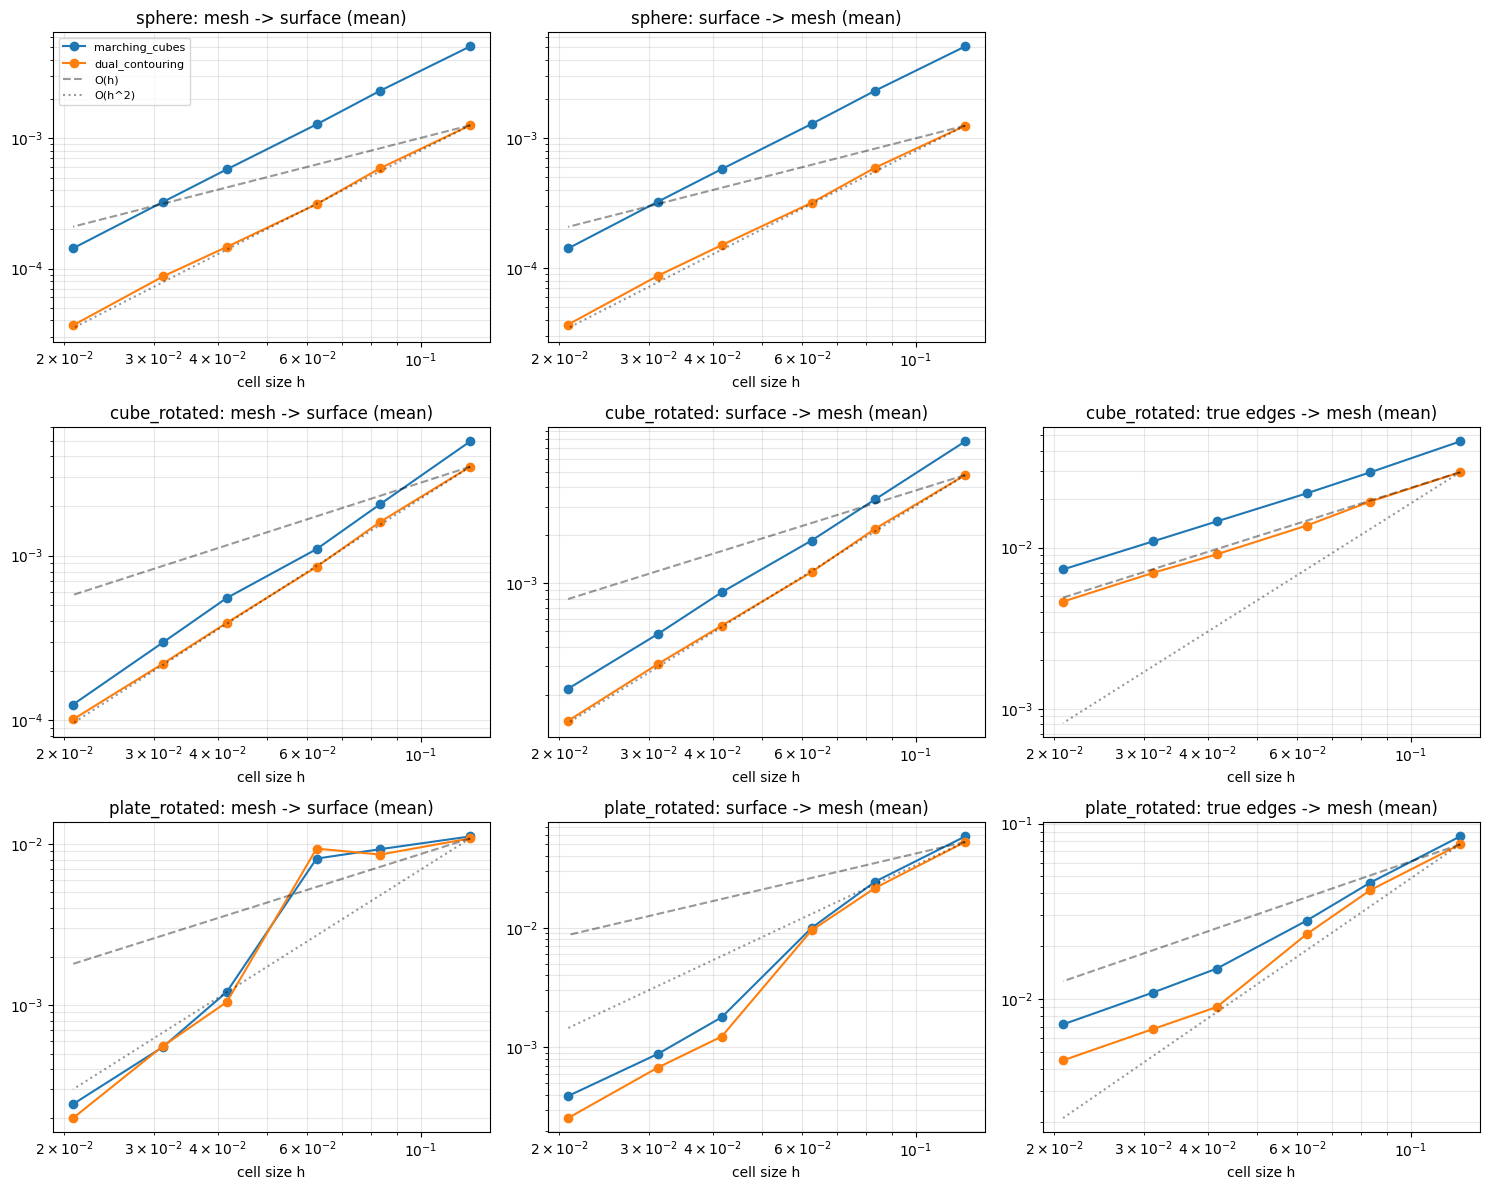

In [5]:
os.makedirs("figures", exist_ok=True)
metrics = [("m2s_mean", "mesh -> surface (mean)"), ("s2m_mean", "surface -> mesh (mean)"), ("edge_mean", "true edges -> mesh (mean)")]
fig, axes = plt.subplots(len(shapes), 3, figsize=(15, 4 * len(shapes)))
for r, sh in enumerate(shapes):
    for cidx, (key, title) in enumerate(metrics):
        ax = axes[r, cidx]
        d0 = res[res["shape"] == sh.name]
        if d0[key].isna().all():
            ax.axis("off"); continue
        for name in METHODS:
            d = d0[d0.method == name].sort_values("n")
            ax.loglog(d.h, d[key], marker="o", label=name)
        h0 = d0[d0.method == "dual_contouring"].sort_values("n")
        hh = h0.h.values; y0 = h0[key].values[0]
        ax.loglog(hh, y0 * hh / hh[0], "k--", alpha=.4, label="O(h)")
        ax.loglog(hh, y0 * (hh / hh[0]) ** 2, "k:", alpha=.4, label="O(h^2)")
        ax.set_title(f"{sh.name}: {title}"); ax.set_xlabel("cell size h"); ax.grid(True, which="both", alpha=.3)
        if r == 0 and cidx == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/resolution_sweep.png", dpi=200); plt.show()

# Step 4: Experiment 2, noisy SDF samples

Gaussian noise with standard deviation `sigma * h` is added to every SDF sample (n = 48). Each setting is repeated with several random draws; the table shows mean and standard deviation across draws.

                                          m2s_mean          s2m_mean          edge_mean          manifold_fraction         
                                              mean      std     mean      std      mean      std              mean      std
shape         method          sigma_cells                                                                                  
cube_rotated  dual_contouring 0.00         0.00041      NaN  0.00056      NaN   0.00912      NaN           1.00000      NaN
                              0.02         0.00067  0.00001  0.00079  0.00002   0.00913  0.00008           0.99985  0.00006
                              0.05         0.00111  0.00002  0.00125  0.00003   0.00927  0.00023           0.99968  0.00014
                              0.10         0.00194  0.00004  0.00205  0.00004   0.00953  0.00032           0.99924  0.00031
                              0.20         0.00372  0.00006  0.00371  0.00006   0.01032  0.00057           0.99566  0.00063
        

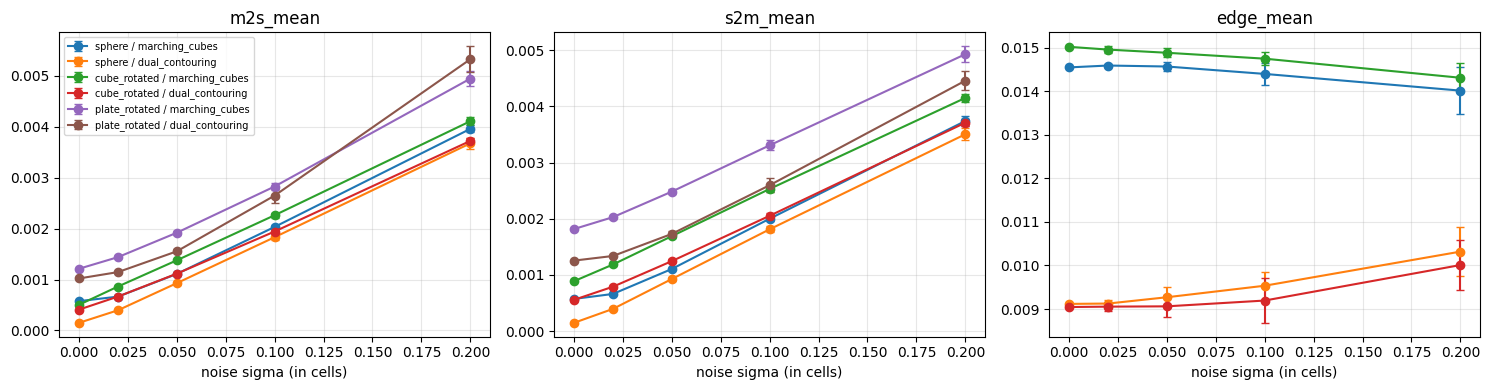

In [6]:
N_NOISE, SIGMAS, DRAWS = 48, [0.0, 0.02, 0.05, 0.1, 0.2], 5
noise_rows = []
for sh in shapes:
    for s in SIGMAS:
        for draw in range(DRAWS if s > 0 else 1):
            f, h = sample_grid(sh, N_NOISE, s, np.random.default_rng(100 + draw))
            for name, fn in METHODS.items():
                V, F = fn(f, h)
                m = mesh_metrics(V, F, sh, np.random.default_rng(draw)); m.update(shape=sh.name, method=name, sigma_cells=s, draw=draw)
                noise_rows.append(m)
noise = pd.DataFrame(noise_rows)
noise.to_csv("results_noise.csv", index=False)
agg = noise.groupby(["shape", "method", "sigma_cells"])[["m2s_mean", "s2m_mean", "edge_mean", "manifold_fraction"]].agg(["mean", "std"]).round(5)
print(agg.to_string())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key in zip(axes, ["m2s_mean", "s2m_mean", "edge_mean"]):
    for sh in shapes:
        for name in METHODS:
            d = noise[(noise["shape"] == sh.name) & (noise.method == name)].groupby("sigma_cells")[key].agg(["mean", "std"])
            if d["mean"].isna().all(): continue
            ax.errorbar(d.index, d["mean"], yerr=d["std"].fillna(0), marker="o", capsize=3, label=f"{sh.name} / {name}")
    ax.set_title(key); ax.set_xlabel("noise sigma (in cells)"); ax.grid(True, alpha=.3)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig("figures/noise_robustness.png", dpi=200); plt.show()

# Step 5: Experiment 3, ablations on the rotated cube

(a) QEF regularization strength. (b) Estimated grid normals vs. oracle analytic normals. Oracle normals are not available for real SDF data; this only tests whether normal estimation limits classic DC here.

In [7]:
cube = shapes[1]
abl = []
for n in [32, 64, 96]:
    f, h = sample_grid(cube, n)
    for reg in [1e-3, 1e-2, 1e-1, 1.0]:
        V, F = mesh_dual_contouring(f, h, reg=reg)
        m = mesh_metrics(V, F, cube, np.random.default_rng(1)); m.update(n=n, variant=f"grid normals, reg={reg:g}"); abl.append(m)
    V, F = mesh_dual_contouring(f, h, reg=0.1, normal_fn=analytic_normal_fn(cube))
    m = mesh_metrics(V, F, cube, np.random.default_rng(1)); m.update(n=n, variant="ORACLE analytic normals, reg=0.1"); abl.append(m)
    V, F = mesh_marching_cubes(f, h)
    m = mesh_metrics(V, F, cube, np.random.default_rng(1)); m.update(n=n, variant="marching cubes"); abl.append(m)
abl = pd.DataFrame(abl); abl.to_csv("results_ablation.csv", index=False)
print(abl[["n", "variant", "m2s_mean", "s2m_mean", "edge_mean", "edge_max"]].round(5).to_string(index=False))

 n                          variant  m2s_mean  s2m_mean  edge_mean  edge_max
32          grid normals, reg=0.001   0.00092   0.00119    0.01336   0.03008
32           grid normals, reg=0.01   0.00075   0.00104    0.01286   0.02485
32            grid normals, reg=0.1   0.00085   0.00117    0.01368   0.02642
32              grid normals, reg=1   0.00119   0.00163    0.01724   0.03255
32 ORACLE analytic normals, reg=0.1   0.00046   0.00049    0.00555   0.02039
32                   marching cubes   0.00109   0.00185    0.02168   0.04144
64          grid normals, reg=0.001   0.00026   0.00033    0.00713   0.01641
64           grid normals, reg=0.01   0.00020   0.00028    0.00661   0.01648
64            grid normals, reg=0.1   0.00022   0.00031    0.00697   0.01699
64              grid normals, reg=1   0.00030   0.00043    0.00877   0.01881
64 ORACLE analytic normals, reg=0.1   0.00012   0.00013    0.00293   0.01042
64                   marching cubes   0.00030   0.00048    0.01092   0.02389

# Step 6: Visual comparison (for the README)

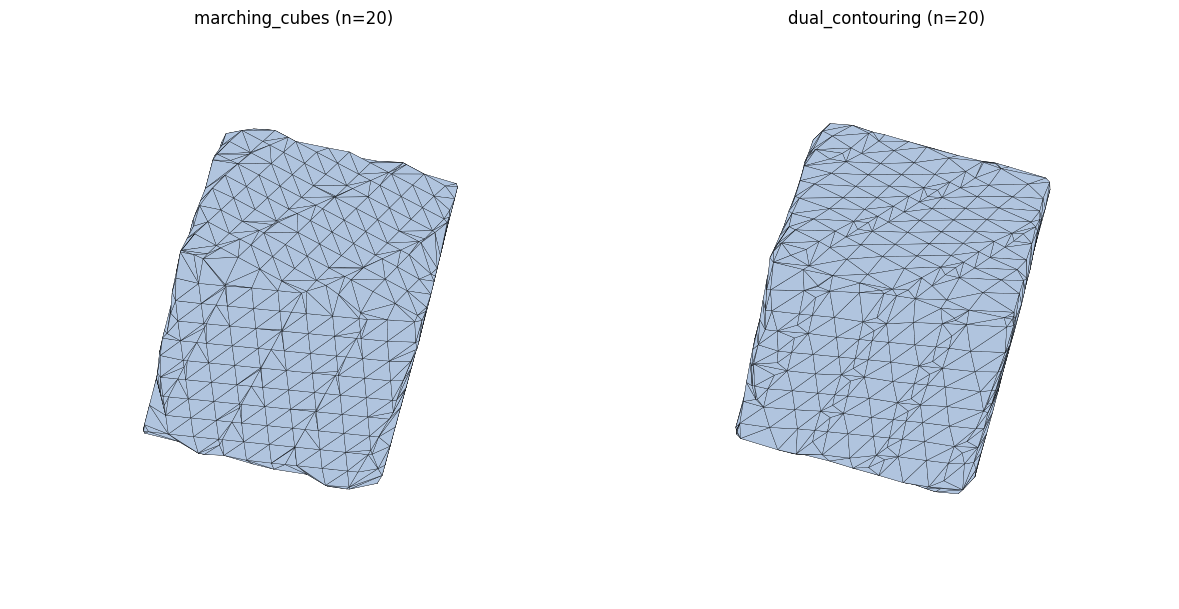

In [8]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
f, h = sample_grid(cube, 20)
fig = plt.figure(figsize=(12, 6))
for k, (name, fn) in enumerate(METHODS.items()):
    V, F = fn(f, h)
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.add_collection3d(Poly3DCollection(V[F], facecolor="lightsteelblue", edgecolor="k", linewidths=0.2, alpha=1.0))
    ax.set_xlim(-.7, .7); ax.set_ylim(-.7, .7); ax.set_zlim(-.7, .7); ax.set_box_aspect((1, 1, 1))
    ax.set_title(f"{name} (n=20)"); ax.axis("off")
plt.tight_layout(); plt.savefig("figures/mesh_comparison.png", dpi=200); plt.show()